# Q-Learning vs SARSA on `PureKinematicGrid`

Two tabular TD-control agents learn to fly the full pylon course in `2D_Kinematics_Demo.py`, controlling both tangential acceleration and turn rate (all 35 actions: 5 acceleration bins from 0 to 4.92 m/s² × 7 turn rates from −30 to +30 °/s). They differ only in the bootstrap target:

- **Q-Learning** (off-policy): `r + γ · max_a Q(s', a)`
- **SARSA** (on-policy): `r + γ · Q(s', a')`, where `a'` is the ε-greedy action actually taken next

In [1]:
import importlib.util
import sys
from pathlib import Path

import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# The file name starts with a digit, so load it by path
sys.path.insert(0, str(Path.cwd()))
spec = importlib.util.spec_from_file_location("kinematics_demo", "2D_Kinematics_Demo.py")
kinematics_demo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(kinematics_demo)

## Environment for a Q-table

The environment file is used unchanged; these wrappers adapt it:

- **Course placement.** The course YAML puts the pylons outside the flyable box, so the grid is widened to 101 m and the pylons (and the gates, which share their arrays) are shifted inside it by `COURSE_OFFSET`.
- **Start position.** The YAML has no start pose, only `start_on_finish_cross: true` (the lap clock starts at the first G1 crossing). The archive branch's fixed-wing sim spawns the aircraft at map (20, −5) facing west, inside the course, and its reference controller (`sim_tecs_ros_xtrack.py`) begins its loop at (−10, −5) and flies west out through G1. `START` is map (−15, −7.5), flying west, which matches that.
- **`RaceRewards`.** `step()` still returns a reward of 0 and never advances gate progress, so the wrapper calls the env's own `calculate_reward`, checks pylon hits along the physics substeps, and ends the episode on a hit or a finished lap. Overspeeding and hitting a pylon also cost `CRASH_PENALTY`. Without it, crashing on purpose right after G1 was the best policy (stalling did that before braking was removed).
- **`GateRelativeObservation`.** The state describes the course from the aircraft's point of view, not its map position:

  | Feature | Bins |
  |---|---|
  | gates passed `q` | 0 to 6 |
  | bearing to the next gate's midpoint, relative to heading | 12 × 30° |
  | distance to that midpoint | edges at 5, 10, 20, 40 m |
  | speed | edges every 0.5 m/s from 5.0 to 7.5 m/s |
  | bearing to the gate after next, relative to heading | 6 × 60° |

  "Gate 30° left, 10–20 m away, flying fast" calls for the same control wherever it happens, so what is learned on one leg carries over to the others. Speed is in the state because the turn radius grows with it (9.2 m at cruise, 15.3 m at 8 m/s). The env has no braking and no drag (every acceleration bin is ≥ 0), so speed only rises from 4.83 m/s toward the 8 m/s overspeed limit: the agent has about 3.2 m/s to spend over the whole lap and has to decide where. Also, the gate after next lets the agent set up its line through the current gate. That is 14,700 states × 35 actions. An absolute `(x, y, heading)` grid needed about 21M entries and never got past gate 3.
- **Exploring starts.** With `explore_prob > 0`, that fraction of training episodes start at a random position, heading, gate stage and a speed between cruise and 7.5 m/s, so later legs get practised without first flying the earlier ones.

In [2]:
COURSE_OFFSET = np.array([45.0, 65.0])
# Reference loop flown by the archive branch's sample controller (sim_tecs_ros_xtrack.py), map frame
REFERENCE_LINE = np.array([(-10, -5), (-30, -10), (-30, -40), (30, -30), (30, 5), (10, 5), (-10, -5)]) + COURSE_OFFSET
START = dict(x=30.0, y=57.5, speed=4.83, psi_deg=180.0)  # inside the course just east of G1, flying west (see below)
CRASH_PENALTY = -20000.0                                  # same as out_of_bounds


def segment_distances(path, centers):
    """Closest distance from each center to a polyline (vectorized race_env.pylon_distances)."""
    path = np.asarray(path, dtype=float)
    a, ab = path[:-1, None, :], np.diff(path, axis=0)[:, None, :]
    t = np.clip(np.sum((centers - a) * ab, axis=-1) / np.maximum(np.sum(ab * ab, axis=-1), 1e-12), 0.0, 1.0)
    return np.linalg.norm(centers - (a + t[..., None] * ab), axis=-1).min(axis=0)


class RaceRewards(gym.Wrapper):
    def step(self, action):
        obs, _, terminated, truncated, info = self.env.step(action)
        base = self.env.unwrapped
        path = base._last_step_path
        distances = segment_distances(path, np.array([p["xy"] for p in base.PYLONS]))
        hit = bool(np.any(distances <= [p["r"] for p in base.PYLONS]))
        reward, parts, event = base.calculate_reward(None, info["prev_xy"], info["new_xy"],
                                                     base.race_env.pylon_robustness(distances),
                                                     hit, info["out_of_bounds"], path=path)
        if hit or info["stalled"] or info["overspeed"]:
            reward += CRASH_PENALTY
        obs[4] = base.q  # calculate_reward may have just advanced q
        info.update(hit_pylon=hit, q=base.q, min_pylon_m=float(distances.min()), **event)
        return obs, reward, terminated or hit or event["lap_finished"], truncated, info


class GateRelativeObservation(gym.ObservationWrapper):
    DIST_EDGES = np.array([5.0, 10.0, 20.0, 40.0])
    SPEED_EDGES = np.arange(5.0, 8.0, 0.5)  # speed only rises from 4.83 to 8 m/s
    N_BEARING, N_NEXT_BEARING = 12, 6

    def __init__(self, env):
        super().__init__(env)
        self.observation_space = spaces.MultiDiscrete([
            env.unwrapped.n_gates + 1, self.N_BEARING, len(self.DIST_EDGES) + 1,
            len(self.SPEED_EDGES) + 1, self.N_NEXT_BEARING])
        self.explore_prob = 0.0

    def reset(self, *, seed=None, options=None):
        base, rng = self.env.unwrapped, np.random.default_rng(seed)
        if rng.random() < self.explore_prob:
            start = dict(x=rng.uniform(10, base.grid_size - 11), y=rng.uniform(10, base.grid_size - 11),
                         speed=rng.uniform(base.v_cruise, 7.5), psi_deg=rng.uniform(-180, 180))
            q = int(rng.integers(base.n_gates + 1))
        else:
            start, q = START, 0
        obs, info = base.reset(seed=seed, **start)
        base.q = obs[4] = q
        return self.observation(obs), info

    @staticmethod
    def relative_bearing(target, x, y, psi, n_bins):
        d = target - np.array([x, y])
        rel = (np.arctan2(d[1], d[0]) - psi + np.pi) % (2 * np.pi) - np.pi
        return int((rel + np.pi) / (2 * np.pi) * n_bins) % n_bins, float(np.hypot(*d))

    def observation(self, obs):
        x, y, speed, psi, q = obs[:5]
        gates = self.env.unwrapped.GATES
        midpoint = lambda k: (gates[k % len(gates)]["p1"] + gates[k % len(gates)]["p2"]) / 2
        bearing, distance = self.relative_bearing(midpoint(int(q)), x, y, psi, self.N_BEARING)
        next_bearing, _ = self.relative_bearing(midpoint(int(q) + 1), x, y, psi, self.N_NEXT_BEARING)
        return (int(q), bearing, int(np.digitize(distance, self.DIST_EDGES)),
                int(np.digitize(speed, self.SPEED_EDGES)), next_bearing)


def make_env():
    env = kinematics_demo.PureKinematicGrid(grid_size=101)
    for pylon in env.PYLONS:
        pylon["xy"] += COURSE_OFFSET
    return GateRelativeObservation(RaceRewards(env))

## Q-Learning and SARSA

- Rewards are scaled by `1e-3` before the update to keep Q-values small. Only `terminated` cuts the bootstrap; a timeout (`truncated`) does not.
- Ties are broken randomly. `np.argmax` would always pick action 0, so every unvisited state got the same default action (in the earlier env that was a full brake, which stalled the aircraft).
- ε decays over the first half of training, then stays at 0.05.
- **Exploration only turns.** A random exploratory action is one of the 7 zero-acceleration actions, picked at random. With no braking, a uniformly random action accelerates 80% of the time, and over a 400-step lap ε-noise alone adds about 4 m/s, more than the 3.2 m/s margin before overspeed. With uniform exploration no training episode finished a lap in 40k episodes. The agent still tries every acceleration action, because untried actions win greedy ties.
- **Checkpointing.** With a constant α the greedy policy keeps swinging (20/20 laps at one check, 0/20 at the next), so every `eval_every` episodes the greedy policy flies from the real start on 20 seeds, and the table with the most laps (ties broken by lap time) is returned.

In [3]:
def epsilon_greedy(Q, s, eps, rng, explore_actions=None):
    if rng.random() < eps:
        if explore_actions is None:
            return int(rng.integers(Q.shape[-1]))
        return int(explore_actions[int(rng.integers(len(explore_actions)))])
    q = Q[s]
    return int(rng.choice(np.flatnonzero(q == q.max())))


def greedy_flight(env, Q, seed, record_path=False):
    env.explore_prob = 0.0
    rng = np.random.default_rng(seed)
    s, _ = env.reset(seed=seed)
    path, speeds, min_pylon, done = [env.unwrapped.state[:2].copy()], [], np.inf, False
    while not done:
        s, _, terminated, truncated, info = env.step(epsilon_greedy(Q, s, 0.0, rng))
        min_pylon = min(min_pylon, info["min_pylon_m"])
        if record_path:
            step_path = env.unwrapped._last_step_path[1:]
            path.extend(step_path)
            speeds.extend([info["speed_m_s"]] * len(step_path))
        done = terminated or truncated
    outcome = next((k for k in ("lap_finished", "hit_pylon", "out_of_bounds", "stalled", "overspeed") if info[k]),
                   "timeout")
    return dict(outcome=outcome, time=info["elapsed_time"], min_pylon=min_pylon,
                path=np.asarray(path), speeds=np.asarray(speeds))


def evaluate(env, Q, seeds):
    flights = [greedy_flight(env, Q, seed) for seed in seeds]
    lap_times = [f["time"] for f in flights if f["outcome"] == "lap_finished"]
    return len(lap_times), (np.mean(lap_times) if lap_times else np.inf)


def train(env, method, n_episodes, alpha=0.1, gamma=0.995, eps_end=0.05, reward_scale=1e-3,
          explore_prob=0.5, seed=0, eval_every=1000, eval_seeds=range(1000, 1020)):
    rng = np.random.default_rng(seed)
    Q = np.zeros((*env.observation_space.nvec, env.action_space.n), dtype=np.float32)
    # Random exploration only varies the turn rate; accelerating is left to the greedy choice
    coast_actions = [i for i, (a, _) in env.unwrapped.action_to_control.items() if a == 0.0]
    best_Q, best_score, history = Q.copy(), (-1, 0.0), []

    for ep in range(n_episodes):
        env.explore_prob = explore_prob
        eps = max(eps_end, 1.0 - (1.0 - eps_end) * ep / (0.5 * n_episodes))
        s, _ = env.reset(seed=seed + ep)
        a = epsilon_greedy(Q, s, eps, rng, coast_actions)
        done = False

        while not done:
            s2, r, terminated, truncated, info = env.step(a)
            a2 = epsilon_greedy(Q, s2, eps, rng, coast_actions)

            if method == "q_learning":
                next_value = Q[s2].max()       # best action at s'
            else:
                next_value = Q[s2 + (a2,)]     # action SARSA will actually take at s'

            target = r * reward_scale + gamma * next_value * (not terminated)
            Q[s + (a,)] += alpha * (target - Q[s + (a,)])
            s, a, done = s2, a2, terminated or truncated

        if (ep + 1) % eval_every == 0:
            laps, lap_time = evaluate(env, Q, eval_seeds)
            history.append((ep + 1, laps))
            if (laps, -lap_time) > best_score:
                best_score, best_Q = (laps, -lap_time), Q.copy()
            if (ep + 1) % (5 * eval_every) == 0:
                print(f"[{method}] ep {ep + 1:>6}  eps {eps:.2f}  greedy laps {laps}/{len(eval_seeds)}  "
                      f"best {best_score[0]}/{len(eval_seeds)} at {-best_score[1]:.1f}s")

    return best_Q, np.array(history)

## Training

40,000 episodes per method, roughly 10–15 minutes each.

In [4]:
N_EPISODES = 40_000
q_env, sarsa_env = make_env(), make_env()
Q_qlearning, hist_qlearning = train(q_env, "q_learning", N_EPISODES)
Q_sarsa, hist_sarsa = train(sarsa_env, "sarsa", N_EPISODES)

[q_learning] ep   5000  eps 0.76  greedy laps 0/20  best 0/20 at infs


[q_learning] ep  10000  eps 0.53  greedy laps 0/20  best 0/20 at infs


[q_learning] ep  15000  eps 0.29  greedy laps 0/20  best 0/20 at infs


[q_learning] ep  20000  eps 0.05  greedy laps 1/20  best 1/20 at 37.2s


[q_learning] ep  25000  eps 0.05  greedy laps 8/20  best 8/20 at 37.6s


[q_learning] ep  30000  eps 0.05  greedy laps 0/20  best 15/20 at 37.0s


... (6 outputs left out)

[sarsa] ep  25000  eps 0.05  greedy laps 20/20  best 20/20 at 31.3s


[sarsa] ep  30000  eps 0.05  greedy laps 0/20  best 20/20 at 31.3s


[sarsa] ep  35000  eps 0.05  greedy laps 9/20  best 20/20 at 31.3s


[sarsa] ep  40000  eps 0.05  greedy laps 12/20  best 20/20 at 31.3s


## Results

The best checkpoint of each method flies from the real start on 50 seeds that were not used to pick the checkpoint (the seeds vary the sensor noise). Left: greedy laps at each checkpoint during training. Right: one greedy lap per agent, coloured by speed; the dashed line is the archive controller's reference loop for comparison.

Q-Learning  laps 48/50  mean lap 35.0s  mean closest pylon pass 2.3 m


SARSA       laps 47/50  mean lap 31.3s  mean closest pylon pass 2.5 m


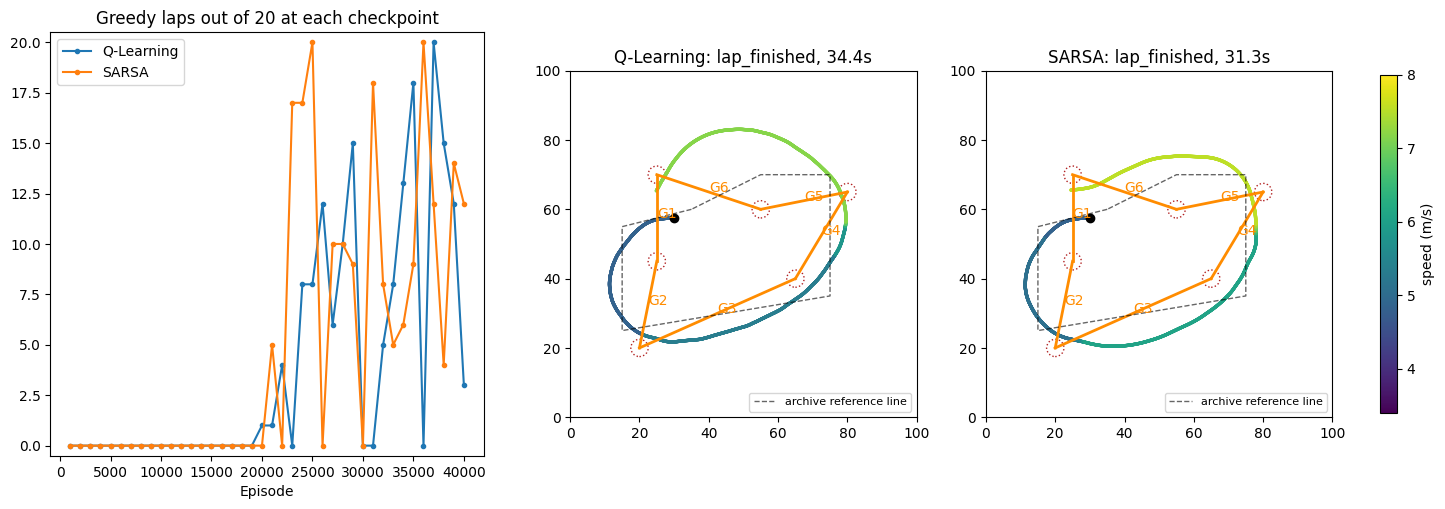

In [5]:
agents = (("Q-Learning", q_env, Q_qlearning, hist_qlearning), ("SARSA", sarsa_env, Q_sarsa, hist_sarsa))
HELD_OUT = range(5000, 5050)
for label, env, Q, _ in agents:
    flights = [greedy_flight(env, Q, seed) for seed in HELD_OUT]
    laps = [f for f in flights if f["outcome"] == "lap_finished"]
    print(f"{label:<11} laps {len(laps)}/{len(flights)}  "
          f"mean lap {np.mean([f['time'] for f in laps]):.1f}s  "
          f"mean closest pylon pass {np.mean([f['min_pylon'] for f in laps]):.1f} m")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for label, _, _, hist in agents:
    axes[0].plot(hist[:, 0], hist[:, 1], marker=".", label=label)
axes[0].set(title="Greedy laps out of 20 at each checkpoint", xlabel="Episode", ylim=(-0.5, 20.5))
axes[0].legend()

for ax, (label, env, Q, _) in zip(axes[1:], agents):
    base = env.unwrapped
    for gate in base.GATES:
        ends = np.array([gate["p1"], gate["p2"]])
        ax.plot(ends[:, 0], ends[:, 1], color="darkorange", linewidth=2)
        ax.text(*ends.mean(axis=0), gate["name"], color="darkorange")
    for pylon in base.PYLONS:
        ax.add_patch(plt.Circle(pylon["xy"], base.PYLON_FIELD_R_M, fill=False, color="firebrick", linestyle=":"))
    ax.plot(REFERENCE_LINE[:, 0], REFERENCE_LINE[:, 1], "k--", linewidth=1, alpha=0.6, label="archive reference line")
    flight = greedy_flight(env, Q, HELD_OUT[0], record_path=True)
    points = ax.scatter(flight["path"][1:, 0], flight["path"][1:, 1], c=flight["speeds"], cmap="viridis",
                        vmin=base.v_min, vmax=base.v_max, s=2)
    ax.plot(START["x"], START["y"], "ko")
    ax.set(xlim=(0, base.grid_size - 1), ylim=(0, base.grid_size - 1), aspect="equal",
           title=f"{label}: {flight['outcome']}, {flight['time']:.1f}s")
    ax.legend(loc="lower right", fontsize=8)
fig.colorbar(points, ax=axes[1:], label="speed (m/s)", shrink=0.8)